<img src="static/demo_qrcode.png" width="90" align="right">

# ScaleFM Demo on Scaling Analysis for NanoTabPFN

A **scaling analysis** answers: *if I train with 20x more compute, what loss will I get,
and how should I scale the model and the hyperparameters?* This notebook analyzes the scaling behavior of **NanoTabPFN** on a surrogate benchmark built from thousands of real training runs.

Where this notebook gets to, extrapolating 20x beyond the largest run:

<table>
  <tr>
    <td align="center"><img src="static/loss_over_cost.png" width="360"><br><b>Loss</b>: a power law through the compute-loss frontier</td>
    <td align="center"><img src="static/total_cells_over_cost.png" width="360"><br><b>A hyperparameter</b>: the data, <code>total_cells</code>, of the frontier runs and the extrapolated point</td>
  </tr>
</table>

ScaleFM automates that with these five components:

1. **Search space.** `scalefm.PipelineSpace` declares the hyperparameters, their types and their scales (linear or log). Some are compute-scaling parameters (`is_compute_scaling=True`), such as the model size; the others are ordinary hyperparameters, such as the learning rate.
2. **Acquisition.** Decides which small runs to train within a compute budget.
3. **Prediction.** Fits a model to the acquired runs and predicts the loss, the compute-optimal model
   size and data, and a full config at any target compute.
4. **Running at scale.** Training runs can be handed off to jobs and distributed over GPUs, with native support for PyTorch DDP.
5. **Visualization.** The scaling fits of the loss, of every downstream metric and of each hyperparameter are plotted automatically in the study directory.

## Installation
Requires Python 3.11+. In Colab, run the cell below; locally, see the
[README](README.md).

In [ ]:
%%capture
%cd /content
!rm -rf /content/scalefm_repo
!git clone --depth 1 https://github.com/automl/scalefm.git /content/scalefm_repo
%cd /content/scalefm_repo/tutorials
!uv pip install --system -e "/content/scalefm_repo"
# Surrogate benchmark of TabPFN: it makes every run take a fraction of a second.
# scan-bench depends on all of autogluon; only the parts it imports are installed.
!uv pip install --system --no-deps scan-bench
!uv pip install --system autogluon.tabular tabpfn xgboost lightgbm seaborn scikit-learn tqdm
# The editable install is only seen after a kernel restart, so it is put on the path
import sys; sys.path[:0] = ["/content/scalefm_repo", "/content/scalefm_repo/tutorials"]

In [1]:
import logging
import os

# The surrogates run in forked worker processes later on, which needs a single
# OpenMP thread (set before they load)
os.environ["OMP_NUM_THREADS"] = "1"
import warnings
warnings.filterwarnings("ignore")
import multiprocessing as mp
import shutil
import subprocess
import sys
import time
from pathlib import Path
from IPython.display import Image, display
from scan_bench import TabPFNTarget

import scalefm
import tabpfn_scan_bench as tabpfn

logging.getLogger("scalefm").setLevel(logging.INFO)


def show(*images, width=480):
    """Show PNG files, e.g. the plots of a run's `summary/`."""
    for image in images:
        display(Image(filename=image, width=width))

## The evaluation pipeline

`evaluate_pipeline` is the function `scalefm.acquire` calls with every config. It
trains a model and returns what the scaling analysis needs: the loss to minimize, the
training cost, the model size and data, and optionally downstream performances and
the inference cost.

Here, the surrogate benchmark of `scan_bench` stands in for the training: it predicts
what a TabPFN training run would reach: its validation loss, and as a downstream
metric its negative log-likelihood on real tabular datasets.

In [2]:
%%capture
loss_benchmark = tabpfn.get_benchmark(TabPFNTarget.VAL_LOSS)
nll_benchmark = tabpfn.get_benchmark(TabPFNTarget.NLL)

In [3]:

def evaluate_pipeline(**config) -> dict:
    """Train TabPFN with `config`, here: ask the surrogates what it would reach."""
    run = tabpfn.build_config(**config)
    flops_per_cell = tabpfn.flops_estimator(**{**config, "total_cells": 1})
    return {
        "objective_to_minimize": loss_benchmark.query(run)["predictions"]["mean"],
        "cost": flops_per_cell * run.total_cells,  # Training FLOPs
        "inference_cost": flops_per_cell / 3,  # FLOPs of a forward pass over one cell
        "n_params": tabpfn.parameters_estimator(**config),
        "n_data": run.total_cells,
        "downstream_performances": {
            "real_nll": nll_benchmark.query(run)["predictions"]["mean"]
        },
    }

In [4]:
config = dict(total_cells=2**25, effective_batch_size=64, lr=1e-3, embedding_size=16, num_layers=4)
evaluate_pipeline(**config)

{'objective_to_minimize': 1.094,
 'cost': 5459968705691.68,
 'inference_cost': 54239.91586458365,
 'n_params': 19402,
 'n_data': 33554432,
 'downstream_performances': {'real_nll': 1.047}}

The benchmark also gives the model size and the training cost of a config without
running it. `acquire` uses the cost estimator to keep every run within
`max_cost_per_config`, and `predict` uses both to turn a predicted model size into a
config.

In [5]:
print(f"{tabpfn.parameters_estimator(**config):.3e} parameters")
print(f"{tabpfn.flops_estimator(**config):.3e} FLOPs")

1.940e+04 parameters
5.460e+12 FLOPs


## The search space

The search space is the most important design decision in a study. It defines every
parameter of a run: its type, its scale (log, linear, ...), its range and its
constraints. If it is badly defined, no optimizer can make up for it. Mark the
parameters that drive compute cost with `is_compute_scaling=True`: the scaling
optimizers lay out their runs along these axes.

The model size is determined by `embedding_size` and `num_layers`, the amount of data by
`total_cells`.

In [6]:
class TabPFNSpace(scalefm.PipelineSpace):
    # Compute-scaling parameters
    total_cells = scalefm.Integer(2**20, 2**35, log=True, log_base=2, is_compute_scaling=True)
    embedding_size = scalefm.Integer(4, 256, log=True, log_base=2, is_compute_scaling=True)
    num_layers = scalefm.Integer(2, 32, log=True, log_base=2, is_compute_scaling=True)
    # The other hyperparameters
    effective_batch_size = scalefm.Integer(16, 256, log=True, log_base=2)
    lr = scalefm.Float(1e-4, 5e-2, log=True)

Every acquisition gets the same FLOP budget, at most a twentieth of it per run, and we
predict at a target of about 20x the cost of the largest run.

In [7]:
RESULTS = Path("results")

MAX_COST_PER_RUN = 2.8e14
BUDGET = MAX_COST_PER_RUN * 20
TARGETS = [5.6e15]  # About 20x the cost of the largest run

## Acquisition and extrapolation

![Data acquisition, then extrapolation to the loss, model size and full config at the target FLOPs](static/scaling_pipeline.png)

A study has two steps. The **acquisition** trains the small runs within the budget.
The **extrapolation**, `scalefm.predict`, fits a predictor to them and predicts at
the target compute up to three things, each harder than the last:

* the best loss $L^*$, in the field `loss` of each `Prediction`,
* the compute-optimal model size $N^*$ and data $D^*$, in `n_params` and `n_data`,
* the full config $\lambda^*$ to train, with every hyperparameter, in `config`.

Not every predictor gives all three:

| predictor | fits | $L^*$ | $N^*$ | $\lambda^*$ | comment |
|---|---|---|---|---|---|
| `chinchilla3` | Chinchilla's law $L(N, D)$ | yes | yes | no | - |
| `power_law` | straight lines in log-log through the frontier runs | yes | yes | yes | ignores the joint dependency of the hyperparameters |
| `gp_posterior` | a Gaussian process over the full config | yes | yes | yes | - |

With `predictor="auto"`, the default, `predict` uses the predictor of the
optimizer that acquired the runs: `chinchilla3` for Chinchilla, `power_law` for
random search, `gp_posterior` for ScAn.

## 1. Chinchilla approach 1

Chinchilla's approach 1 trains a ladder of model sizes, each on a few multiples of
its parameter count in cells (`data_multipliers`), and grows the models until the
budget is spent. From these runs it reads off the lowest loss at each compute, the
compute-optimal frontier. Like the Chinchilla paper, it keeps a fixed training recipe,
so it runs on a version of the space with constant hyperparameters:

In [8]:
class TabPFNChinchillaSpace(scalefm.PipelineSpace):
    # Compute-scaling parameters
    total_cells = scalefm.Integer(2**20, 2**35, log=True, log_base=2, is_compute_scaling=True)
    embedding_size = scalefm.Integer(4, 256, log=True, log_base=2, is_compute_scaling=True)
    # The other hyperparameters, fixed
    num_layers = 2  # scalefm.Integer(2, 32, log=True, log_base=2, is_compute_scaling=True)
    effective_batch_size = 64  # scalefm.Integer(16, 256, log=True, log_base=2)
    lr = 1e-3  # scalefm.Float(1e-4, 5e-2, log=True)


CHINCHILLA1 = RESULTS / "chinchilla1"

tabpfn.set_seed(0)
scalefm.acquire(
    evaluate_pipeline=evaluate_pipeline,
    pipeline_space=TabPFNChinchillaSpace(),
    root_directory=CHINCHILLA1,
    optimizer=(
        "chinchilla",
        {
            "strategy": "approach1",
            "data_parameter_name": "total_cells",
            "params_estimator": tabpfn.parameters_estimator,
            "data_multipliers": [300, 1e3, 3e3, 1e4],
        },
    ),
    cost_estimator=tabpfn.flops_estimator,
    total_cost_to_spend=BUDGET,
    overwrite_root_directory=True,
)

### Loss and model size with `chinchilla3`

`scalefm.predict` reads the runs back from the root directory and fits the
predictor of the optimizer, here Chinchilla's approach 3 law $L(N, D)$:

In [9]:
chinchilla_predictions = scalefm.predict(CHINCHILLA1, target_costs=TARGETS, target_inference_costs=[1e7])
for target, prediction in zip(TARGETS, chinchilla_predictions):
    print(f"C={target:.1e}: loss {prediction.loss:.3f},"
          f" N*={prediction.n_params:.2e}, D*={prediction.n_data:.2e}")
    print("config:", prediction.config)  # None, the Chinchilla fit doesn't model the space

C=5.6e+15: loss 0.903, N*=3.84e+05, D*=2.43e+09
config: None


### The scaling plots

`predict` also saves plots of its fit to `summary/`: every run, the compute-loss
frontier, and the fit, with the predictions at the target costs:

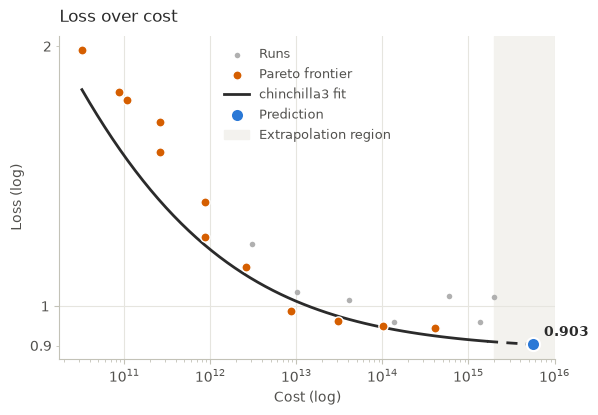

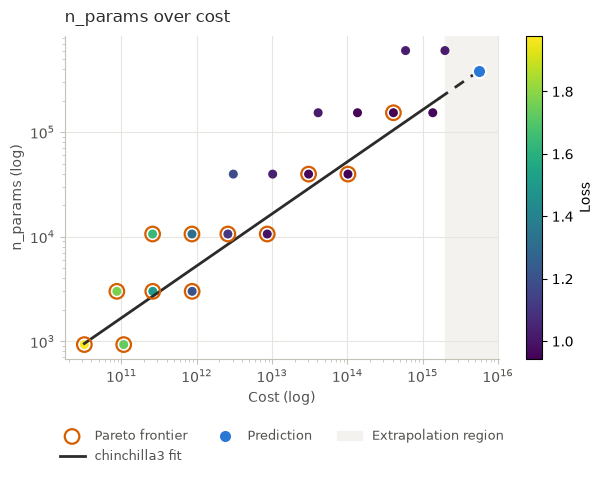

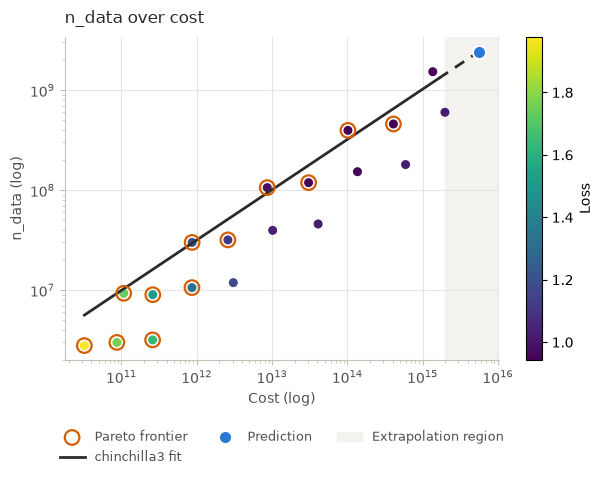

In [10]:
show(CHINCHILLA1 / "summary/pre_train/loss_over_cost.png",
     *[CHINCHILLA1 / f"summary/pre_train/parameters/{name}_over_cost.png"
       for name in ["n_params", "n_data"]])

The config is `None`: the $L(N, D)$ fit doesn't model the hyperparameters. The next
section falls back to `power_law`, which fits every hyperparameter and predicts its
value at each target.

## 2. The default scaling pipeline

By default, `acquire` samples configs uniformly at random from the whole space, each
costing at most `max_cost_per_config`, and `predict` then fits `power_law`, which also
predicts every hyperparameter.

C=5.6e+15: loss 0.899, N*=7.02e+05, D*=1.33e+09
config: {'effective_batch_size': 256, 'embedding_size': 4, 'lr': 0.0007235590019263327, 'num_layers': 4, 'total_cells': 34359738368}


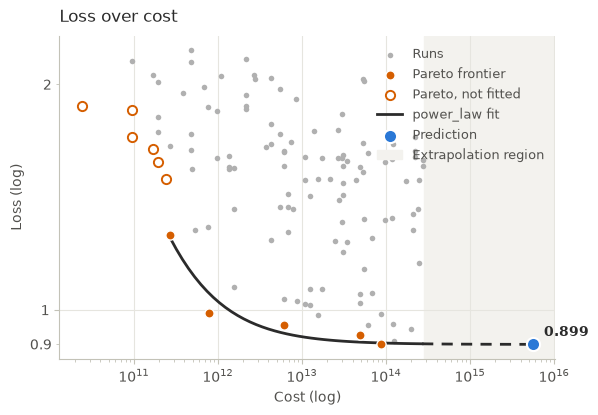

In [11]:
DEFAULT = RESULTS / "default"

tabpfn.set_seed(0)
scalefm.acquire(
    evaluate_pipeline=evaluate_pipeline,
    pipeline_space=TabPFNSpace(),
    root_directory=DEFAULT,
    cost_estimator=tabpfn.flops_estimator,
    max_cost_per_config=MAX_COST_PER_RUN,
    total_cost_to_spend=BUDGET,
    overwrite_root_directory=True,
)

predictions = scalefm.predict(DEFAULT, target_costs=TARGETS, target_inference_costs=[1e8])
for target, prediction in zip(TARGETS, predictions):
    print(f"C={target:.1e}: loss {prediction.loss:.3f},"
          f" N*={prediction.n_params:.2e}, D*={prediction.n_data:.2e}")
    print("config:", prediction.config)
show(DEFAULT / "summary/pre_train/loss_over_cost.png")

### The individual hyperparameters

Every hyperparameter gets its own fit over the frontier runs, and a prediction at
each target:

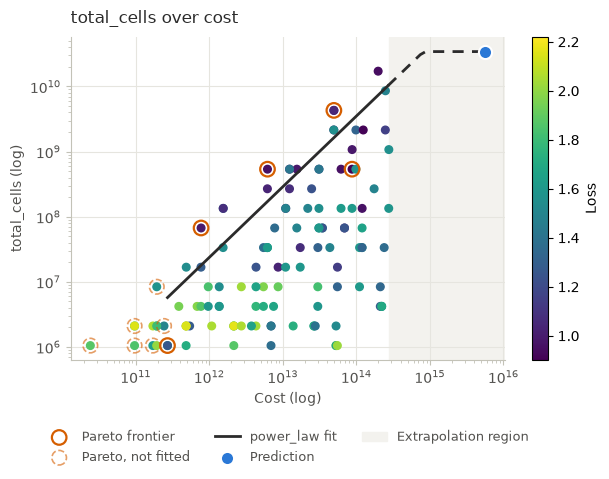

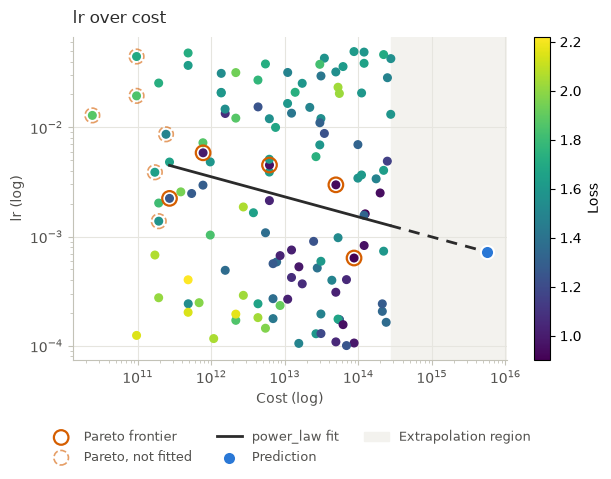

In [12]:
show(*[DEFAULT / f"summary/pre_train/parameters/{name}_over_cost.png"
       for name in ["total_cells", "lr"]],
     width=420)

The prediction at each target (loss, model size, data and config) is saved as a
CSV table next to the plots:

In [13]:
print((DEFAULT / "summary/pre_train/predictions_over_cost.csv").read_text())

target_cost,loss,n_params,n_data,effective_batch_size,embedding_size,lr,num_layers,total_cells
5600000000000000.0,0.8992869407371271,701688.3224288566,1330125218.7048657,256,4,0.0007235590019263327,4,34359738368



### Downstream performance

Every metric in `downstream_performances` gets its own fit, through the Pareto-optimal
runs of that metric:

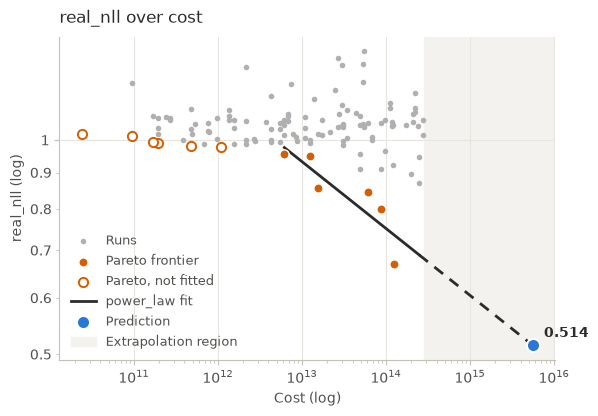

In [14]:
show(DEFAULT / "summary/downstream/real_nll/real_nll_over_cost.png")

### Inference cost

When the runs report an `inference_cost`, the loss is also plotted over it, showing
the best loss reached at each inference cost:

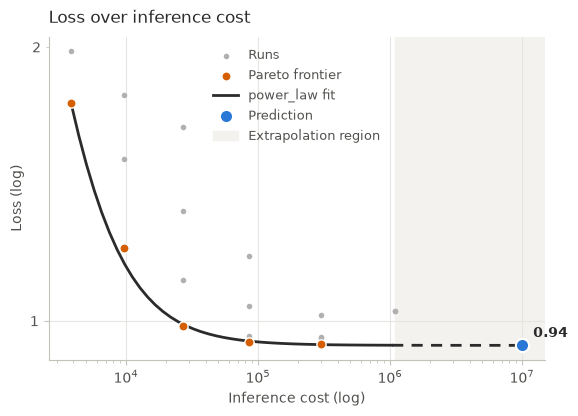

In [21]:
show(CHINCHILLA1 / "summary/pre_train/loss_over_inference_cost.png")

## 3. Parallel workers [for you to try!]

A real study runs many trainings at once. With ScaleFM you start the same
`acquire` call several times, as processes on the same machine, or as Slurm jobs on
different machines, all pointing at one `root_directory`: the workers share its FLOP
budget through the filesystem.

To give the runs a training time, `timed_evaluate_pipeline` waits as long as training
would take on a small simulated cluster. Below are three workers as processes of this
notebook (forked, as on Linux and Colab; on macOS or Windows run the `acquire` call
from a script in several terminals instead).

In [16]:
PARALLEL = RESULTS / "parallel"
shutil.rmtree(PARALLEL, ignore_errors=True)


def timed_evaluate_pipeline(**config) -> dict:
    """`evaluate_pipeline`, taking as long as training on the simulated cluster."""
    result = evaluate_pipeline(**config)
    time.sleep(result["cost"] / tabpfn.SIMULATED_FLOPS_PER_SECOND)
    return result


def run_worker():
    scalefm.acquire(
        evaluate_pipeline=timed_evaluate_pipeline,
        pipeline_space=TabPFNSpace(),
        root_directory=PARALLEL,
        cost_estimator=tabpfn.flops_estimator,
        max_cost_per_config=MAX_COST_PER_RUN,
        total_cost_to_spend=BUDGET,
    )


processes = [mp.Process(target=run_worker) for _ in range(3)]
for p in processes:
    p.start()
for p in processes:
    p.join()

The three workers split the runs between them:

In [17]:
full, _ = scalefm.status(PARALLEL)
training_time = (full["cost"] / tabpfn.SIMULATED_FLOPS_PER_SECOND).sum()
wall_clock = full["time_end"].max() - full["time_sampled"].min()
print(f"{full['cost'].sum():.2e} FLOPs spent of {BUDGET:.2e}")
print(f"training time {training_time:.0f}s, wall clock {wall_clock:.0f}s")
full.groupby("evaluating_worker_id")["cost"].agg(runs="count", flops="sum")

5.78e+15 FLOPs spent of 5.60e+15
training time 289s, wall clock 102s


,runs,flops
evaluating_worker_id,,
worker_0,37,1905529974419655.75
worker_1,37,1989431293541129.0
worker_2,46,1883443351792521.25


## 4. Asynchronous sampling and multi-GPU jobs [for you to try!]

On a cluster you rarely keep a worker alive for the whole study. Instead you sample
configs, hand each one to a job sized for it, and collect the results as the jobs
finish:

* With **`is_async=True`**, `acquire` only samples.
* **`scalefm.fetch_pending_trials`** gives the pending configs, and
  **`scalefm.mark_trial_evaluating`** marks one as taken once its job is launched.
* The job reads the config, trains it, and reports its result into the study with
  **`scalefm.save_pipeline_results`**.

A job can also train its config on several GPUs with **PyTorch DDP**: `torchrun`
starts one process per GPU, all of them train, and only rank 0 reports, so a
multi-GPU run is still one trial.

In [18]:
ASYNC = (RESULTS / "async").resolve()
shutil.rmtree(ASYNC, ignore_errors=True)


def sample(n_configs):
    """Sample `n_configs` configs, without training them."""
    scalefm.acquire(
        pipeline_space=TabPFNSpace(),
        root_directory=ASYNC,
        is_async=True,
        cost_estimator=tabpfn.flops_estimator,
        max_cost_per_config=MAX_COST_PER_RUN,
        total_cost_to_spend=BUDGET,
        # Pending configs have no cost yet, so bound each round by its size
        worker_evaluations_to_spend=n_configs,
    )


sample(4)
print("pending:", [trial_id for trial_id, _ in scalefm.fetch_pending_trials(ASYNC, n=4)])

pending: ['0', '1', '2', '3']


The job script reads its config from `config.yaml`. Every rank runs it, and rank 0
reports. It reports the cost itself, as the `cost_estimator` of `acquire` only fills
in the cost of results returned by an `evaluate_pipeline`:

In [19]:
JOB = '''
import sys, time
import torch
import torch.distributed as dist
import yaml

import scalefm
import tabpfn_scan_bench as tabpfn

root, trial_id = sys.argv[1], sys.argv[2]
dist.init_process_group("gloo")  # "nccl" on GPUs
rank, world_size = dist.get_rank(), dist.get_world_size()

with open(f"{root}/configs/config_{trial_id}/config.yaml") as f:
    config = yaml.safe_load(f)
# Train: each rank works on its share of the batch, then the gradients are averaged
seconds = tabpfn.flops_estimator(**config) / tabpfn.SIMULATED_FLOPS_PER_SECOND
time.sleep(seconds / world_size)
gradient = torch.full((4,), float(rank))
dist.all_reduce(gradient)

if rank == 0:
    run = tabpfn.build_config(**config)
    result = {
        "objective_to_minimize": tabpfn.get_benchmark().query(run)["predictions"]["mean"],
        "cost": tabpfn.flops_estimator(**config),
        "n_params": tabpfn.parameters_estimator(**config),
        "n_data": run.total_cells,
        "info_dict": {"world_size": world_size},
    }
    scalefm.save_pipeline_results(result, pipeline_id=trial_id, root_directory=root)
dist.destroy_process_group()
'''
job_script = ASYNC / "job.py"
job_script.write_text(JOB)


def submit(trial_id, gpus=2):
    """Stands in for `sbatch`: runs the job on this machine, in the background."""
    env = {**os.environ, "PYTHONPATH": str(Path(tabpfn.__file__).parent)}
    return subprocess.Popen(
        [sys.executable, "-m", "torch.distributed.run", "--standalone",
         f"--nproc_per_node={gpus}", str(job_script), str(ASYNC), trial_id],
        env=env, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
    )


def run_pending():
    """Submit a job for every pending config, and wait for their exit codes."""
    jobs = {}
    for trial_id, _config in scalefm.fetch_pending_trials(ASYNC, n=4):
        # Taken by a job, so it is not fetched again
        scalefm.mark_trial_evaluating(ASYNC, trial_id, worker_id=f"job-{trial_id}")
        jobs[trial_id] = submit(trial_id)
    return {trial_id: job.wait() for trial_id, job in jobs.items()}


print("round 1, exit codes:", run_pending())
sample(4)  # The next round, within the same budget
print("round 2, exit codes:", run_pending())

round 1, exit codes: {'0': 0, '1': 0, '2': 0, '3': 0}
round 2, exit codes: {'4': 0, '5': 0, '6': 0, '7': 0}


Every job reported from rank 0 of its two processes, into the same study:

In [20]:
full, _ = scalefm.status(ASYNC)
full[["config.embedding_size", "config.num_layers", "config.total_cells",
      "objective_to_minimize", "cost", "extra.world_size"]].sort_values("cost")

,config.embedding_size,config.num_layers,config.total_cells,objective_to_minimize,cost,extra.world_size
id,,,,,,
1,4,8,1048576,1.954,48144581162.975273,2
0,8,16,8388608,1.865,1935046927846.841553,2
2,32,4,8388608,1.299,4313274118137.760254,2
6,16,2,134217728,1.196,10942371182444.916016,2
7,4,8,536870912,1.063,24650025555443.339844,2
4,128,8,2097152,1.959,27603359568887.78125,2
3,128,16,4194304,1.295,110368106573769.5625,2
5,32,32,33554432,1.585,137799505750475.859375,2


## Takeaways

1. **Define** the pipeline and space, **acquire** runs within a FLOP budget,
   **predict** at the target compute.
2. **Predict** loss, model size and data, and a full config (`power_law` or
   `gp_posterior`; not `chinchilla3`), for the loss and every downstream metric.
3. Check the scaling plots in `summary/`, over the training and the inference cost.
4. **Parallelization**: workers share one budget, async jobs report back, DDP works.